## Processing Kassel dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

#### Load count data and gff file

In [2]:
df = pd.read_csv('../nf_output/countData/countData.tsv', sep='\t', comment = '#', index_col = 'Geneid')
df.head()

,Chr,Start,End,Strand,Length,DMSO-3_sorted.bam,AUF-1_sorted.bam,TRANS-2_sorted.bam,TRANS-1_sorted.bam,TRANS-3_sorted.bam,AUF-3_sorted.bam,CIS-2_sorted.bam,AUF-2_sorted.bam,Control-1_sorted.bam,CIS-1_sorted.bam,DMSO-2_sorted.bam,DMSO-1_sorted.bam,CIS-3_sorted.bam,Control-3_sorted.bam,Control-2_sorted.bam
Geneid,,,,,,,,,,,,,,,,,,,,
Gm26206,NC_000067.7,3172239,3172348,+,110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Xkr4,NC_000067.7;NC_000067.7;NC_000067.7;NC_000067....,3269956;3283662;3284705;3393039;3420932;349192...,3277540;3287191;3287191;3393983;3422536;349212...,-;-;-;-;-;-;-;-;-;-;-;-;-,14824,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Gm53491,NC_000067.7;NC_000067.7;NC_000067.7;NC_000067....,3363896;3365064;3396936;3422903;3436480;343801...,3364050;3365091;3397056;3438060;3436728;343806...,+;+;+;+;+;+;+;+,24933,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Gm57489,NC_000067.7,3741733,3742701,-,969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Gm27396,NC_000067.7,3854099,3854156,-,58,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [3]:
# Read gff for gene annotation
gff = pd.read_csv('../data/reference/GCF_000001635.27_GRCm39_genomic.gff', comment='#', sep='\t', header=None)
gff.head()

,0,1,2,3,4,5,6,7,8
0,NC_000067.7,RefSeq,region,1,195154279,.,+,.,ID=NC_000067.7:1..195154279;Dbxref=taxon:10090...
1,NC_000067.7,RefSeqFE,enhancer,3132446,3133539,.,.,.,ID=id-GeneID:131295014;Dbxref=GeneID:131295014...
2,NC_000067.7,RefSeqFE,biological_region,3132446,3133539,.,+,.,ID=id-GeneID:131295014-2;Dbxref=GeneID:1312950...
3,NC_000067.7,cmsearch,gene,3172239,3172348,.,+,.,"ID=gene-Gm26206;Dbxref=GeneID:115487594,MGI:MG..."
4,NC_000067.7,cmsearch,snRNA,3172239,3172348,.,+,.,ID=rna-XR_004936710.1;Parent=gene-Gm26206;Dbxr...


In [4]:
# Subset to exons, on which counting was conducted, and extract gene biotype
gff_subset = gff.loc[gff[2] == 'exon']
gff_subset['biotype'] = gff_subset[8].str.split('gbkey=', expand=True)[1]
gff_subset['biotype'] = gff_subset['biotype'].str.split(';', expand=True)[0]
gff_subset.head()

,0,1,2,3,4,5,6,7,8,biotype
5,NC_000067.7,cmsearch,exon,3172239,3172348,.,+,.,ID=exon-XR_004936710.1-1;Parent=rna-XR_0049367...,ncRNA
8,NC_000067.7,Gnomon,exon,3740775,3741733,.,-,.,ID=exon-XM_006495550.5-1;Parent=rna-XM_0064955...,mRNA
9,NC_000067.7,Gnomon,exon,3491925,3492124,.,-,.,ID=exon-XM_006495550.5-2;Parent=rna-XM_0064955...,mRNA
10,NC_000067.7,Gnomon,exon,3283662,3287191,.,-,.,ID=exon-XM_006495550.5-3;Parent=rna-XM_0064955...,mRNA
11,NC_000067.7,Gnomon,exon,3269956,3277540,.,-,.,ID=exon-XM_006495550.5-4;Parent=rna-XM_0064955...,mRNA


In [5]:
# Extract gene symbol
gff_subset['gene'] = gff_subset[8].str.split('gene=', expand=True)[1]
gff_subset['gene'] = gff_subset['gene'].str.split(';', expand=True)[0]
gff_subset.head()

,0,1,2,3,4,5,6,7,8,biotype,gene
5,NC_000067.7,cmsearch,exon,3172239,3172348,.,+,.,ID=exon-XR_004936710.1-1;Parent=rna-XR_0049367...,ncRNA,Gm26206
8,NC_000067.7,Gnomon,exon,3740775,3741733,.,-,.,ID=exon-XM_006495550.5-1;Parent=rna-XM_0064955...,mRNA,Xkr4
9,NC_000067.7,Gnomon,exon,3491925,3492124,.,-,.,ID=exon-XM_006495550.5-2;Parent=rna-XM_0064955...,mRNA,Xkr4
10,NC_000067.7,Gnomon,exon,3283662,3287191,.,-,.,ID=exon-XM_006495550.5-3;Parent=rna-XM_0064955...,mRNA,Xkr4
11,NC_000067.7,Gnomon,exon,3269956,3277540,.,-,.,ID=exon-XM_006495550.5-4;Parent=rna-XM_0064955...,mRNA,Xkr4


In [6]:
# Drop duplicates for unique gene symbols as in counts table
gff_subset.drop_duplicates(subset='gene', inplace=True)
gff_subset.set_index('gene', inplace=True)
gff_subset.head()

,0,1,2,3,4,5,6,7,8,biotype
gene,,,,,,,,,,
Gm26206,NC_000067.7,cmsearch,exon,3172239,3172348,.,+,.,ID=exon-XR_004936710.1-1;Parent=rna-XR_0049367...,ncRNA
Xkr4,NC_000067.7,Gnomon,exon,3740775,3741733,.,-,.,ID=exon-XM_006495550.5-1;Parent=rna-XM_0064955...,mRNA
Gm53491,NC_000067.7,Gnomon,exon,3363896,3364050,.,+,.,ID=exon-XR_004935518.1-1;Parent=rna-XR_0049355...,ncRNA
Gm57489,NC_000067.7,Gnomon,exon,3741733,3742701,.,-,.,ID=id-Gm57489;Parent=gene-Gm57489;Dbxref=GeneI...,exon
Gm27396,NC_000067.7,cmsearch,exon,3854099,3854156,.,-,.,ID=id-Gm27396;Parent=gene-Gm27396;Dbxref=GeneI...,exon


In [7]:
# Add biotype to count data by gene key
merged_df = pd.concat([df, gff_subset['biotype']], axis = 1)
merged_df.head()

,Chr,Start,End,Strand,Length,DMSO-3_sorted.bam,AUF-1_sorted.bam,TRANS-2_sorted.bam,TRANS-1_sorted.bam,TRANS-3_sorted.bam,...,CIS-2_sorted.bam,AUF-2_sorted.bam,Control-1_sorted.bam,CIS-1_sorted.bam,DMSO-2_sorted.bam,DMSO-1_sorted.bam,CIS-3_sorted.bam,Control-3_sorted.bam,Control-2_sorted.bam,biotype
Gm26206,NC_000067.7,3172239,3172348,+,110,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ncRNA
Xkr4,NC_000067.7;NC_000067.7;NC_000067.7;NC_000067....,3269956;3283662;3284705;3393039;3420932;349192...,3277540;3287191;3287191;3393983;3422536;349212...,-;-;-;-;-;-;-;-;-;-;-;-;-,14824,4,0,0,0,0,...,0,0,0,0,0,0,0,0,0,mRNA
Gm53491,NC_000067.7;NC_000067.7;NC_000067.7;NC_000067....,3363896;3365064;3396936;3422903;3436480;343801...,3364050;3365091;3397056;3438060;3436728;343806...,+;+;+;+;+;+;+;+,24933,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ncRNA
Gm57489,NC_000067.7,3741733,3742701,-,969,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,exon
Gm27396,NC_000067.7,3854099,3854156,-,58,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,exon


### Load metadata

In [8]:
meta = pd.read_csv('sample_annotation.csv', sep=';')
# Add a unique sample name
meta.head()

,Sample,Treatment,Replicate
0,Control-1,Control,1
1,Control-2,Control,2
2,Control-3,Control,3
3,DMSO-1,DMSO,1
4,DMSO-2,DMSO,2


#### QC of data

- library size distribution

- fractions of gene_biotypes (gene categories per sample)

- PCA for potential outlier detection

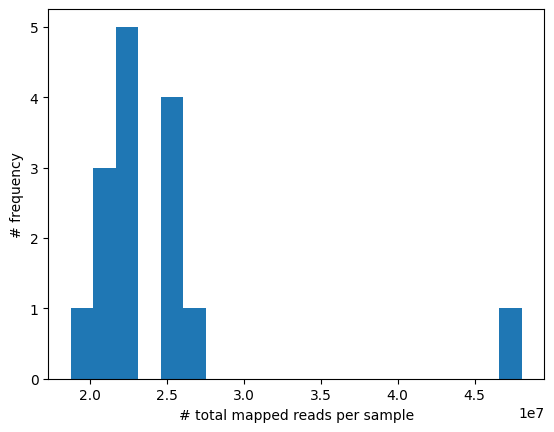

In [9]:
def mapped_read_distribution(df: pd.DataFrame):
    df_work = df.drop(labels = ['Chr', 'Start', 'End', 'Strand', 'Length', 'biotype'], axis = 1)
    mapped_reads = np.sum(df_work, axis = 0)
    plt.hist(mapped_reads, bins=20)
    plt.xlabel('# total mapped reads per sample')
    plt.ylabel('# frequency')

mapped_read_distribution(merged_df)

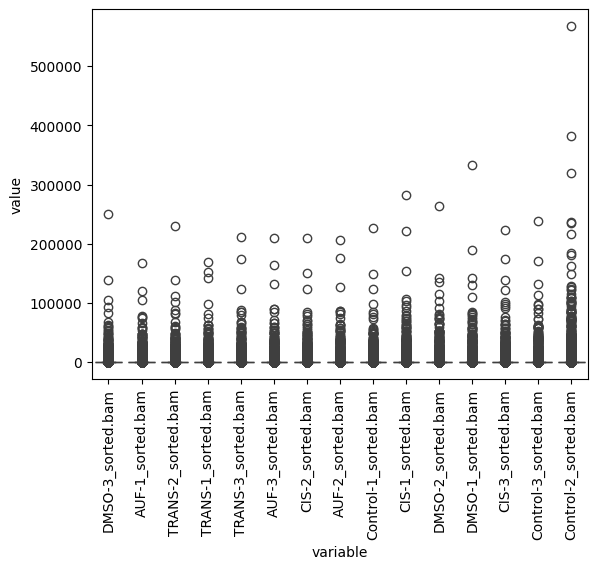

In [10]:
def per_sample_count_distribution(df: pd.DataFrame):
    df_work = df.drop(labels = ['Chr', 'Start', 'End', 'Strand', 'Length', 'biotype'], axis = 1)
    #df_work = df_work.transpose()
    df_work = pd.melt(df_work)

    sns.boxplot(data=df_work, x='variable', y='value')
    plt.xticks(rotation=90)

per_sample_count_distribution(merged_df)

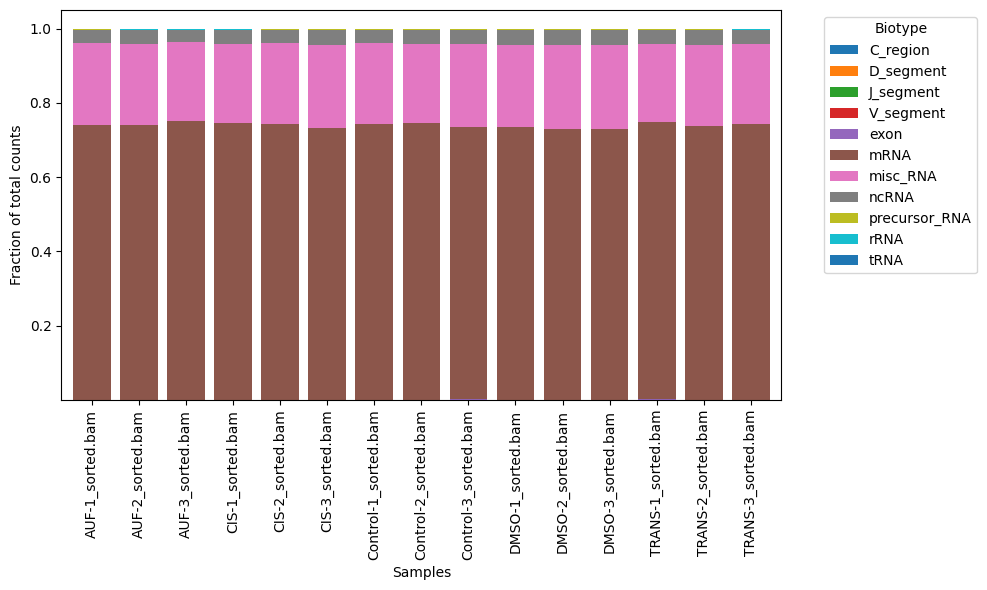

,AUF-1_sorted.bam,AUF-2_sorted.bam,AUF-3_sorted.bam,CIS-1_sorted.bam,CIS-2_sorted.bam,CIS-3_sorted.bam,Control-1_sorted.bam,Control-2_sorted.bam,Control-3_sorted.bam,DMSO-1_sorted.bam,DMSO-2_sorted.bam,DMSO-3_sorted.bam,TRANS-1_sorted.bam,TRANS-2_sorted.bam,TRANS-3_sorted.bam
biotype,,,,,,,,,,,,,,,
C_region,4.913774e-08,1.323194e-07,1.794254e-07,2.288438e-07,8.911170e-08,2.306099e-07,2.398792e-07,8.322998e-08,0.000000e+00,3.939444e-08,4.013058e-08,0.000000e+00,1.034172e-06,9.418459e-08,4.506918e-07
D_segment,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
J_segment,4.913774e-08,0.000000e+00,0.000000e+00,7.628125e-08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.131088e-07,0.000000e+00,0.000000e+00,0.000000e+00
V_segment,6.387906e-07,3.969582e-07,1.345691e-07,3.051250e-07,2.227792e-07,3.843499e-07,7.196377e-07,6.450324e-07,4.002983e-07,0.000000e+00,8.828727e-07,2.663860e-07,8.093518e-07,8.005690e-07,2.253459e-07
exon,1.106877e-03,1.082549e-03,1.076911e-03,1.091089e-03,1.136531e-03,1.173958e-03,1.232020e-03,1.209165e-03,1.312298e-03,1.113799e-03,1.177953e-03,1.112321e-03,1.273155e-03,1.106857e-03,1.160306e-03
mRNA,7.399062e-01,7.397738e-01,7.504158e-01,7.443864e-01,7.414644e-01,7.322251e-01,7.412306e-01,7.439026e-01,7.337957e-01,7.331556e-01,7.271324e-01,7.279367e-01,7.480845e-01,7.378428e-01,7.423132e-01
misc_RNA,2.192335e-01,2.176842e-01,2.115307e-01,2.142293e-01,2.172009e-01,2.225413e-01,2.199483e-01,2.145421e-01,2.220983e-01,2.223944e-01,2.272611e-01,2.267150e-01,2.103020e-01,2.167648e-01,2.144481e-01
ncRNA,3.585841e-02,3.727949e-02,3.274029e-02,3.570199e-02,3.625781e-02,4.044541e-02,3.387186e-02,3.605485e-02,3.900987e-02,3.925692e-02,4.062555e-02,4.016904e-02,3.655923e-02,4.025266e-02,3.766318e-02
precursor_RNA,1.733678e-03,1.649493e-03,1.670944e-03,1.679866e-03,1.700474e-03,1.639598e-03,1.798087e-03,1.837364e-03,1.801703e-03,1.603354e-03,1.705148e-03,1.639233e-03,1.547481e-03,1.665937e-03,1.714341e-03


In [11]:
def plot_biotype_fractions(counts_df, figsize=(10,6), top_n=None):
    """
    Create a stacked barplot showing the fractional contribution of gene biotypes
    to total counts in each sample.

    Parameters
    ----------
    counts_df : pd.DataFrame
    Counts table with genes as rows, samples as columns, and an additional
    column for gene biotypes.
    figsize : tuple
    Size of the matplotlib figure.
    top_n : int or None
    If set, only the top_n most abundant biotypes are shown explicitly,
    others are grouped into "Other".
    """
    # Drop unneccessary columns
    counts_df = counts_df.drop(labels = ['Chr', 'Start', 'End', 'Strand', 'Length'], axis = 1)

    # Separate counts and biotype annotation
    sample_cols = counts_df.columns.difference(['biotype'])
    biotypes = counts_df['biotype']

    # Sum counts by biotype per sample
    summed = counts_df.groupby(biotypes)[sample_cols].sum()

    # Convert to fractional contribution per sample
    fractions = summed.div(summed.sum(axis=0), axis=1)

    # Optionally collapse rare biotypes
    if top_n is not None and top_n < fractions.shape[0]:
        totals = fractions.sum(axis=1).sort_values(ascending=False)
        keep = totals.index[:top_n]
        others = totals.index[top_n:]

        fractions.loc["Other"] = fractions.loc[others].sum()
        fractions = fractions.loc[keep.tolist() + ["Other"]]

    # Plot stacked barplot
    ax = fractions.T.plot(kind="bar", stacked=True, figsize=figsize, width=0.8)
    ax.set_ylabel("Fraction of total counts")
    ax.set_xlabel("Samples")
    ax.legend(title="Biotype", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    return fractions

plot_biotype_fractions(merged_df)

--> Major gene biotypes are misc_RNA, ncRNA, mRNA

#### Data Cleaning

In [12]:
# Perform in silico rRNA,... depletion

def biotype_selection(df: pd.DataFrame, RNA_categories: list):
    
    df = df.drop(labels = ['Chr', 'Start', 'End', 'Strand'], axis = 1)
    
    df_work = df.loc[df['biotype'].isin(RNA_categories)]
    
    return df_work

df_selected = biotype_selection(merged_df, ['mRNA', 'misc_RNA', 'ncRNA'])
df_selected.shape

(38696, 17)

In [13]:
# Select samples of interest

def rename_cols(df, meta):

    df_selected = df.drop(labels=['biotype', 'Length'], axis=1)
    sample_names = [a.split('_')[0] for a in df_selected.columns.tolist()]
    df_selected.columns = sample_names

    df_selected = df_selected[meta['Sample']]

    df_selected[['Length', 'biotype']] = df[['Length', 'biotype']]

    return df_selected

df_selected = rename_cols(df_selected, meta)

# Select samples with low counts

def remove_low_expressed_samples(df, threshold):
    
    df_work = df.drop(labels=['Length', 'biotype'], axis=1)
    samples = df_work.loc[:,np.sum(df_work, axis=0) > threshold].columns.tolist()

    all_cols = samples +['Length', 'biotype']

    return df[all_cols]

df_selected = remove_low_expressed_samples(df_selected, 1e6)
df_selected.head()

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3,Length,biotype
Gm26206,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,110,ncRNA
Xkr4,0,0,0,0,0,4,0,0,0,0,0,0,0,0,0,14824,mRNA
Gm53491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,24933,ncRNA
Rp1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,12004,mRNA
Sox17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5692,mRNA


In [14]:
# Remove genes with low average expression

def remove_low_expressed_genes(df, threshold):
    
    df_work = df.drop(labels=['Length', 'biotype'], axis=1)
    genes = df_work.loc[np.mean(df_work, axis=1) > threshold].index.tolist() # mean > 3 --> expression above 10 in at least 42 samples

    return df.loc[genes]

df_selected = remove_low_expressed_genes(df_selected, 10)
df_selected

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3,Length,biotype
Mrpl15,948,1970,937,890,757,580,723,776,809,1009,787,817,933,690,843,5105,misc_RNA
Lypla1,1331,3014,1522,1704,1795,1418,1330,1513,1408,1969,1361,1590,1596,1386,1535,2503,mRNA
Tcea1,3288,7526,4206,3457,3569,2345,3271,3922,3921,4342,3588,4198,3442,3158,3611,2847,mRNA
Atp6v1h,1972,4607,2386,2457,2324,1886,3019,3362,3292,3505,2835,3365,4100,2778,3102,4357,mRNA
4732440D04Rik,37,91,55,30,89,47,57,72,61,99,72,77,34,43,56,3848,ncRNA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ND4L,7570,20385,9777,11194,11578,8309,7837,12416,10932,13537,11130,11960,7653,9578,11682,297,mRNA
ND4,28551,74760,33889,42137,40477,29281,31799,42472,38219,52479,36429,41527,32891,31245,41461,1378,mRNA
ND5,35551,89868,40908,51136,53269,37637,39015,54273,49432,69197,51042,56913,55233,41628,51396,1824,mRNA
ND6,13754,33142,15696,20252,19291,13864,16202,19698,17091,29195,20312,23040,23024,16110,22047,519,mRNA


In [15]:
df_selected.value_counts('biotype')

biotype
mRNA        9583
misc_RNA    3511
ncRNA       2701
Name: count, dtype: int64

#### TPM normalization

In [16]:
# TPM normalization

def TPM(df, pse):
    """
    df: rRNA depleted input table
    meta: original dataframe including 'Length' column
    pse: pseudocount
    """
    
    lengths = df['Length']
    tpmData = df.drop(labels=['Length', 'biotype'], axis=1)

    for i in range(0,tpmData.shape[1]):
        rpk = (tpmData.iloc[:,i]+pse)/lengths
        scalingfactor = np.sum(rpk)/1000000
        tpm = rpk/scalingfactor

        tpmData.iloc[:,i] = tpm
    
    return tpmData

tpm_data = TPM(df_selected, 0.5)
tpm_data.head()

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3
Mrpl15,23.727834,20.597722,19.651954,18.537162,16.349347,16.720441,18.846815,18.012570,18.578911,19.561000,18.035694,16.844286,20.784179,17.214133,19.317693
Lypla1,67.935507,64.267728,65.091856,72.367109,79.038391,83.331604,70.688572,71.606352,65.931833,77.835123,63.596737,66.839533,72.497392,70.497912,71.722413
Tcea1,147.511839,141.073067,158.111563,129.056472,138.144453,121.140461,152.811006,163.156904,161.385272,150.880404,147.368112,155.119813,137.436090,141.192180,148.308510
Atp6v1h,57.815721,56.430811,58.614368,59.939212,58.783511,63.666430,92.160039,91.391268,88.539562,79.587138,76.088694,81.249859,106.970386,81.159632,83.251133
4732440D04Rik,1.244551,1.268892,1.543434,0.842306,2.562722,1.815097,1.987138,2.231171,1.872575,2.557811,2.202830,2.118494,1.019057,1.438704,1.716640


In [17]:
# Final tpm data

final_tpm = tpm_data

#### Log normalization of tpm data

In [18]:
final_log = np.log2(final_tpm+1)
final_log.head()

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3
Mrpl15,4.628064,4.432807,4.368206,4.288149,4.116809,4.147343,4.310836,4.248882,4.291229,4.361839,4.250635,4.157390,4.445209,4.186986,4.344665
Lypla1,6.107175,6.028298,6.046401,6.197062,6.322620,6.398001,6.163671,6.182024,6.064621,6.300767,6.013389,6.084054,6.199621,6.159829,6.184328
Tcea1,7.214434,7.150489,7.313895,7.022994,7.120440,6.932397,7.265015,7.358932,7.343277,7.246792,7.213037,7.286510,7.113076,7.151698,7.222153
Atp6v1h,5.878130,5.843753,5.897588,5.929299,5.901676,6.014945,6.541639,6.529685,6.484453,6.332478,6.268447,6.361941,6.754492,6.360358,6.396624
4732440D04Rik,1.166427,1.181988,1.346778,0.881513,1.832980,1.493185,1.578764,1.692057,1.522345,1.830990,1.679347,1.640849,1.013681,1.286115,1.441824


#### Extract raw data (important for DESeq2 analysis later on)

In [19]:
df_raw = df_selected.drop(labels=['biotype', 'Length'], axis=1)
df_raw.head()

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3
Mrpl15,948,1970,937,890,757,580,723,776,809,1009,787,817,933,690,843
Lypla1,1331,3014,1522,1704,1795,1418,1330,1513,1408,1969,1361,1590,1596,1386,1535
Tcea1,3288,7526,4206,3457,3569,2345,3271,3922,3921,4342,3588,4198,3442,3158,3611
Atp6v1h,1972,4607,2386,2457,2324,1886,3019,3362,3292,3505,2835,3365,4100,2778,3102
4732440D04Rik,37,91,55,30,89,47,57,72,61,99,72,77,34,43,56


#### Save data with the two low expression samples removed

In [20]:
df_raw.to_csv('Raw_countData.csv')
final_tpm.to_csv('TPM_normalized_countData.csv')
final_log.to_csv('Log2_normalized_countData.csv')

## Visualizing processed data

In [21]:
# Visualization by sample type(s)

def clusterTypes(df, metadata, savefig=False):

    df = df.transpose()
    
    metadata.index = metadata['Sample']
    metaData_final = metadata.loc[df.index.tolist()]

    fig, axs = plt.subplots(1,2, figsize=(6,3))
    # plt.subplots_adjust(hspace=0.15)
    plt.suptitle(f"Analysis of bulk data", fontweight = 'bold', fontsize = 'x-large')
    plt.subplots_adjust(left=0.05, bottom=0.1, right=0.95, top=0.9, wspace=0.45,hspace=0.4)

    pca = PCA(n_components = 2)
    components = pca.fit_transform(df)
    
    labels = metaData_final['Treatment']
    X = pd.DataFrame(pd.concat([pd.DataFrame(components, index=metaData_final.index.to_list()), pd.DataFrame(labels, index=metaData_final.index.to_list()), pd.DataFrame(metaData_final['Replicate'], index=metaData_final.index.to_list())], axis = 1, ignore_index=False))
    X.columns = ["PC1", "PC2", "Treatment", "Replicate"]
    sns.scatterplot(ax = axs[0], x = "PC1", y = "PC2", data = X, hue = "Treatment", style = "Replicate", legend = False, size = 5)
    #sns.move_legend(axs[0,0], "upper left", bbox_to_anchor=(1, 1))
    axs[0].set_title('PCA')

    u = TSNE(n_components = 2, learning_rate = 'auto', init = 'random', perplexity = 10).fit_transform(df)
    labels = metaData_final["Treatment"]
    X = pd.DataFrame(pd.concat([pd.DataFrame(u, index=metaData_final.index.to_list()), pd.DataFrame(labels, index=metaData_final.index.to_list()), pd.DataFrame(metaData_final['Replicate'], index=metaData_final.index.to_list())], axis = 1, ignore_index=False))
    X.columns = ["Dim1", "Dim2", "Treatment", "Replicate"]
    sns.scatterplot(ax = axs[1], x = "Dim1", y = "Dim2", data = X, hue = "Treatment", style = "Replicate", size = 5)
    sns.move_legend(axs[1], "upper left", bbox_to_anchor=(1, 1), ncol = 4, title = 'Sample annotation')
    axs[1].set_title('t-SNE')

    plt.tight_layout()
    if savefig:
        plt.savefig("PCA_tSNE.svg", bbox_inches='tight', dpi=300)
    plt.show()

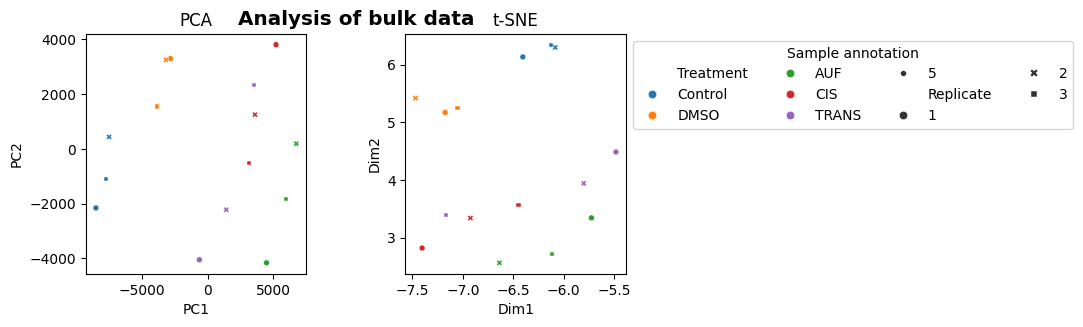

In [22]:
clusterTypes(final_tpm, meta)

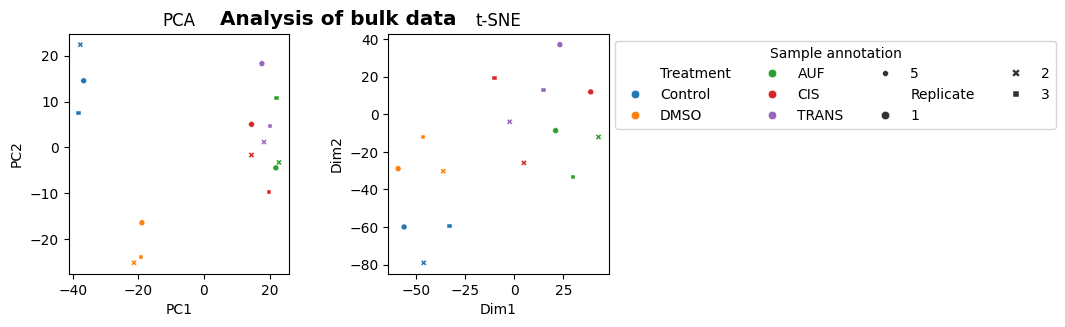

In [24]:
clusterTypes(final_log, meta, True)

In [45]:
# Visualization by sample type(s)

def pca(df, metadata, savefig=False):

    df = df.transpose()
    
    metadata.index = metadata['Sample']
    metaData_final = metadata.loc[df.index.tolist()]

    pca = PCA(n_components = 2)
    components = pca.fit_transform(df)
    
    labels = metaData_final['Treatment']
    X = pd.DataFrame(pd.concat([pd.DataFrame(components, index=metaData_final.index.to_list()), pd.DataFrame(labels, index=metaData_final.index.to_list()), pd.DataFrame(metaData_final['Replicate'], index=metaData_final.index.to_list())], axis = 1, ignore_index=False))
    X.columns = ["PC1", "PC2", "Treatment", "Replicate"]

    plt.subplots(figsize=(8, 3))
    ax = sns.scatterplot(x = "PC1", y = "PC2", data = X, hue = "Treatment", style = "Replicate")
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), ncol = 2, title = 'Sample annotation')
    
    plt.tight_layout()
    if savefig:
        plt.savefig("PCA_only.svg", bbox_inches='tight', dpi=300)
    plt.show()

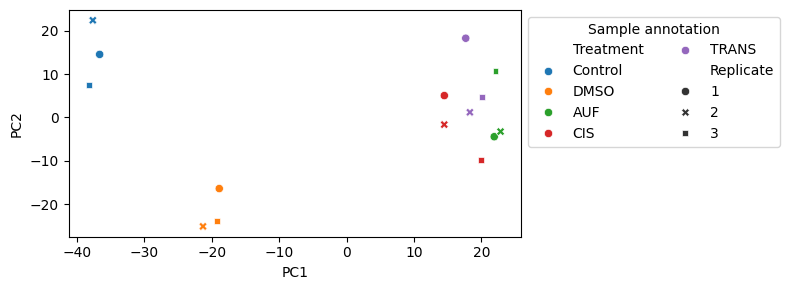

In [46]:
pca(final_log[['Control-1', 'Control-2', 'Control-3',
                                   'DMSO-1', 'DMSO-2', 'DMSO-3',
                                   'AUF-1', 'AUF-2', 'AUF-3',
                                   'CIS-1', 'CIS-2', 'CIS-3',
                                   'TRANS-1', 'TRANS-2', 'TRANS-3']], meta, True)

#### Calculate clustermaps to include further sample information including treatment

In [47]:
def clustermap_treatment_by_state(data, genes, metadata, norm):

    # Format data
    if genes == 'all':
        data_selected = data
    elif isinstance(genes, list):
        data_selected = data.loc[genes] # subset bulk data

    data_selected = data_selected[['Control-1', 'Control-2', 'Control-3',
                                   'DMSO-1', 'DMSO-2', 'DMSO-3',
                                   'AUF-1', 'AUF-2', 'AUF-3',
                                   'CIS-1', 'CIS-2', 'CIS-3',
                                   'TRANS-1', 'TRANS-2', 'TRANS-3']]
    metadata.index = metadata['Sample']
    metadata = metadata.loc[data_selected.columns.tolist()]
    selected_samples = list(metadata['Sample'])
    data_selected = data_selected[selected_samples]

    # Define annotation metadata for columns
    treatment = pd.Series(metadata['Treatment'], index=data_selected.columns, name="Treatment")

    # Map categories to colors
    lut_treat = dict(zip(treatment.unique(), sns.color_palette("Set1", n_colors=treatment.nunique())))

    # Convert categories to colors
    treatment_colors = treatment.map(lut_treat)

    # Combine into a DataFrame (order matters = stacked rows)
    col_colors = pd.Series(treatment_colors, index=data_selected.columns)

    # Create clustermap
    if norm == 'z-score':
        g = sns.clustermap(
            data_selected,
            col_cluster=False,
            row_cluster=True,
            cmap="viridis",
            figsize=(14, 6),
            z_score=0,
            col_colors=col_colors,
        )
    else:
        g = sns.clustermap(
            data_selected,
            col_cluster=False,
            row_cluster=True,
            cmap="viridis",
            figsize=(14, 6),
            col_colors=col_colors,
        )

    # Add legends
    for label in lut_treat:
        g.ax_col_dendrogram.bar(0, 0, color=lut_treat[label], label=f"Treatment: {label}", linewidth=0)
    g.ax_col_dendrogram.legend(loc="center", ncol=2)

    # ---- Add text labels above col_colors ----
    for i, row_label in enumerate(col_colors.index):
        g.ax_col_dendrogram.text(
            -0.02,                                  # X position (slightly to the left)
            (i + 0.5) / len(col_colors.index),      # Y position (centered on row)
            row_label,
            va='center',
            ha='right',
            fontsize=10,
            transform=g.ax_col_dendrogram.transAxes
        )

    return g

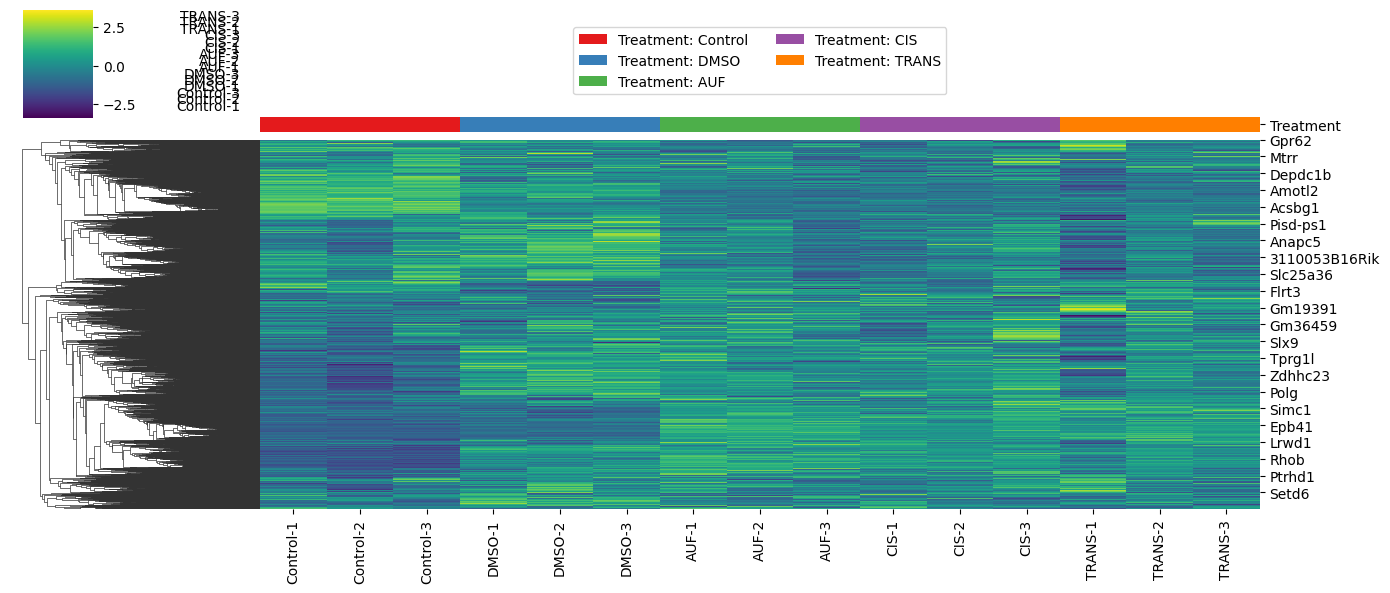

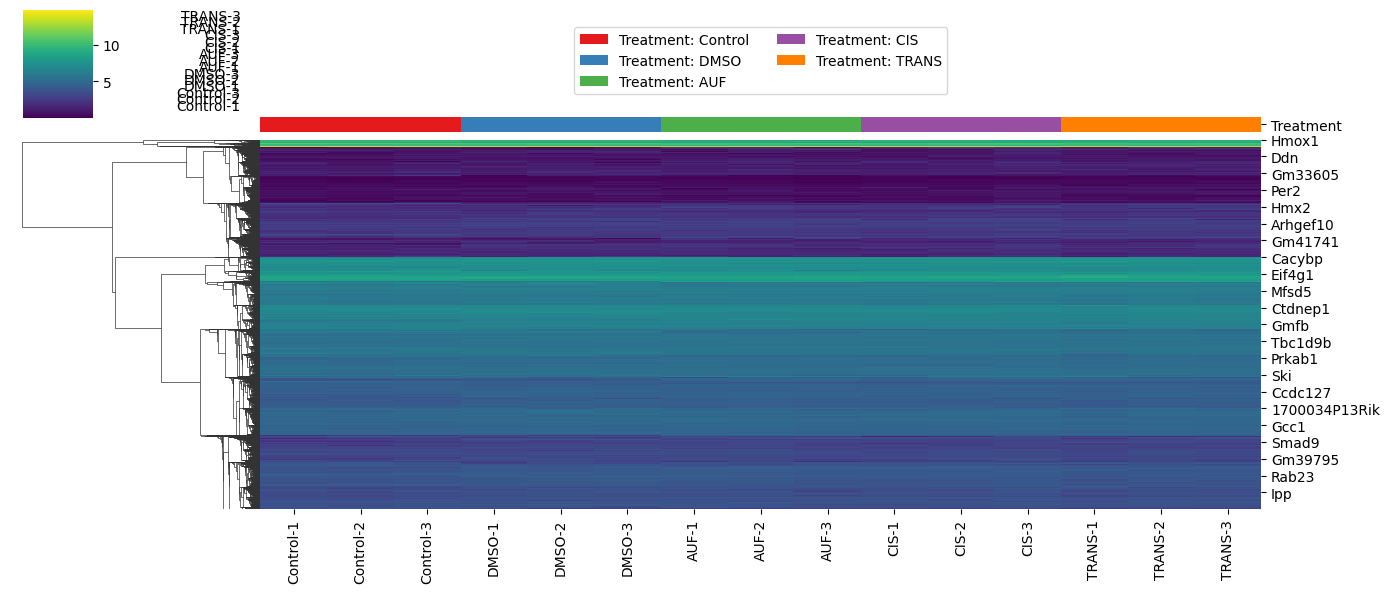

In [50]:
plot = clustermap_treatment_by_state(final_tpm, 'all', meta, 'z-score')
plot.savefig("Heatmap.svg", bbox_inches='tight', dpi=100)
plot.savefig("Heatmap.pdf", bbox_inches='tight', dpi=100)
plot.savefig("Heatmap.png", bbox_inches='tight', dpi=100)
clustermap_treatment_by_state(final_log, 'all', meta, None)

In [25]:
# Clustermap function

def clustermap_summarized(data, metadata, norm):

    # Select samples and adjust metadata and data 
    data_selected = data.reindex(sorted(data.columns), axis=1)
    meta_test = metadata.loc[data_selected.columns.tolist()]
    selected_samples = list(meta_test['Sample'])
    data_selected = data_selected[selected_samples]

    
    # Sample dictionary
    sample_dict = (
        meta_test.groupby("Treatment")["Sample"]
        .apply(list)
        .to_dict()
    )

    # Use the sample_dict to summarize profiles
    tpm_means = {}
    for key in sample_dict.keys():
        samples = sample_dict[key]
        tpm_mean = np.mean(data_selected[samples], axis = 1)
        tpm_means[key] = tpm_mean

    mean_tpm_data = pd.DataFrame(tpm_means, index=data_selected.index.tolist())


    # Create clustermap
    if norm == 'z-score':
        g = sns.clustermap(
            mean_tpm_data,
            col_cluster=True,
            row_cluster=True,
            cmap="viridis",
            figsize=(14, 6),
            z_score=0,
        )
    else:
        g = sns.clustermap(
            mean_tpm_data,
            col_cluster=True,
            row_cluster=True,
            cmap="viridis",
            figsize=(14, 6),
        )


    return g

In [26]:
# Clustermap function
def clustermap_summarized_median(data, metadata, norm):

    # Select samples and adjust metadata and data 
    data_selected = data.reindex(sorted(data.columns), axis=1)
    meta_test = metadata.loc[data_selected.columns.tolist()]
    selected_samples = list(meta_test['Sample'])
    data_selected = data_selected[selected_samples]
    
    # Sample dictionary
    sample_dict = (
        meta_test.groupby("Treatment")["Sample"]
        .apply(list)
        .to_dict()
    )

    # Use the sample_dict to summarize profiles
    tpm_means = {}
    for key in sample_dict.keys():
        samples = sample_dict[key]
        tpm_mean = np.median(data_selected[samples], axis = 1)
        tpm_means[key] = tpm_mean

    mean_tpm_data = pd.DataFrame(tpm_means, index=data_selected.index.tolist())


    # Create clustermap
    if norm == 'z-score':
        g = sns.clustermap(
            mean_tpm_data,
            col_cluster=True,
            row_cluster=True,
            cmap="viridis",
            figsize=(14, 6),
            z_score=0,
        )
    else:
        g = sns.clustermap(
            mean_tpm_data,
            col_cluster=True,
            row_cluster=True,
            cmap="viridis",
            figsize=(14, 6),
        )


    return g

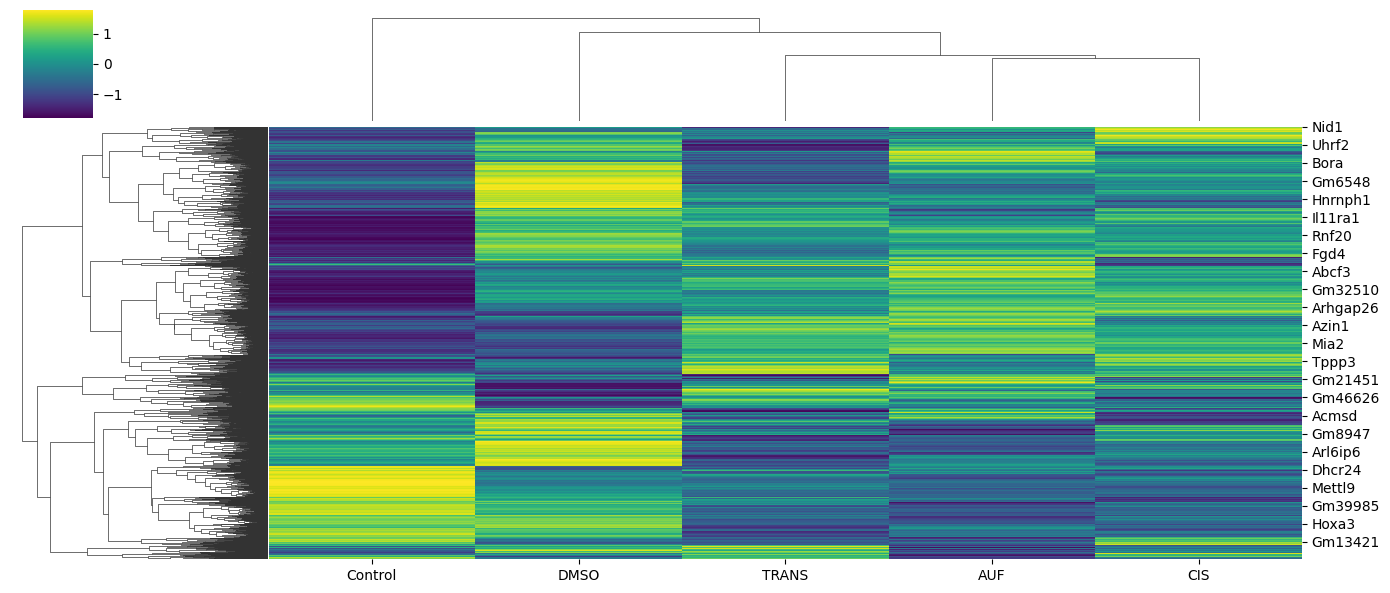

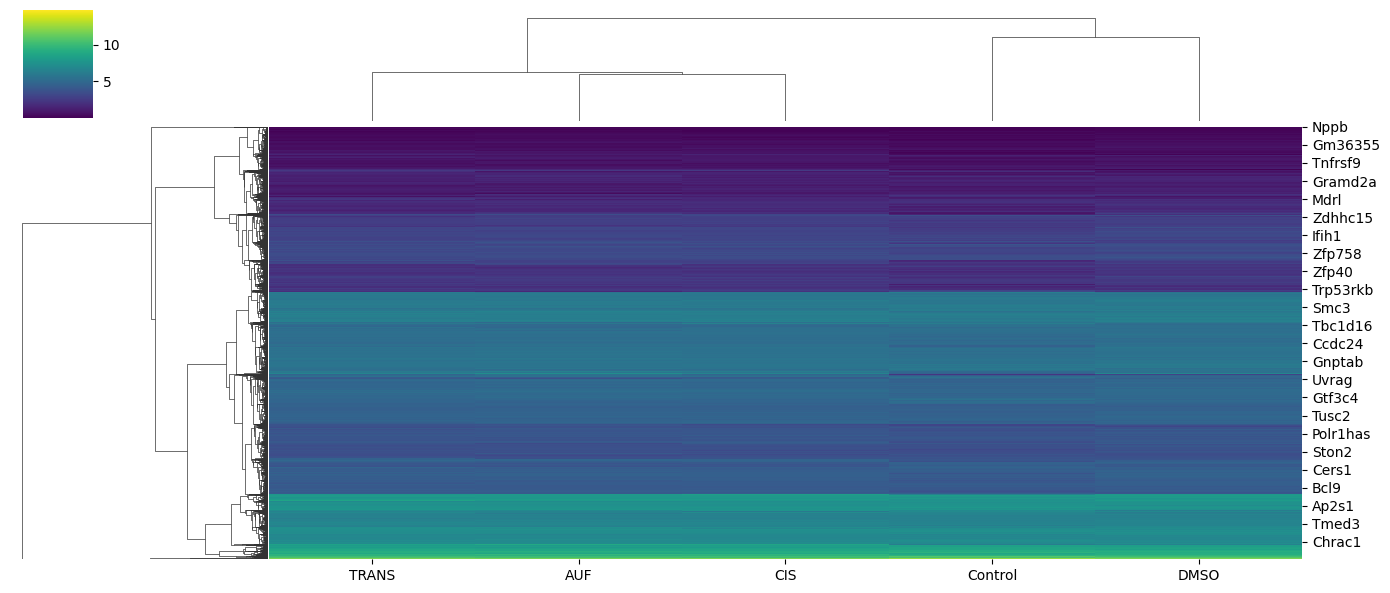

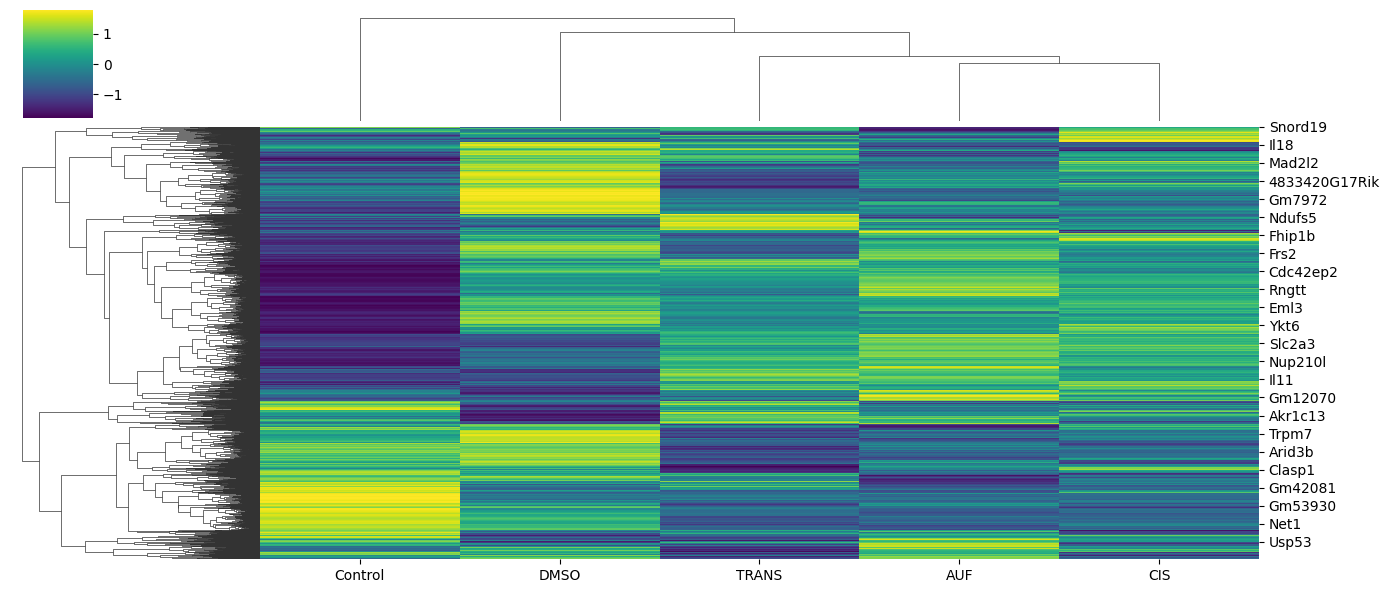

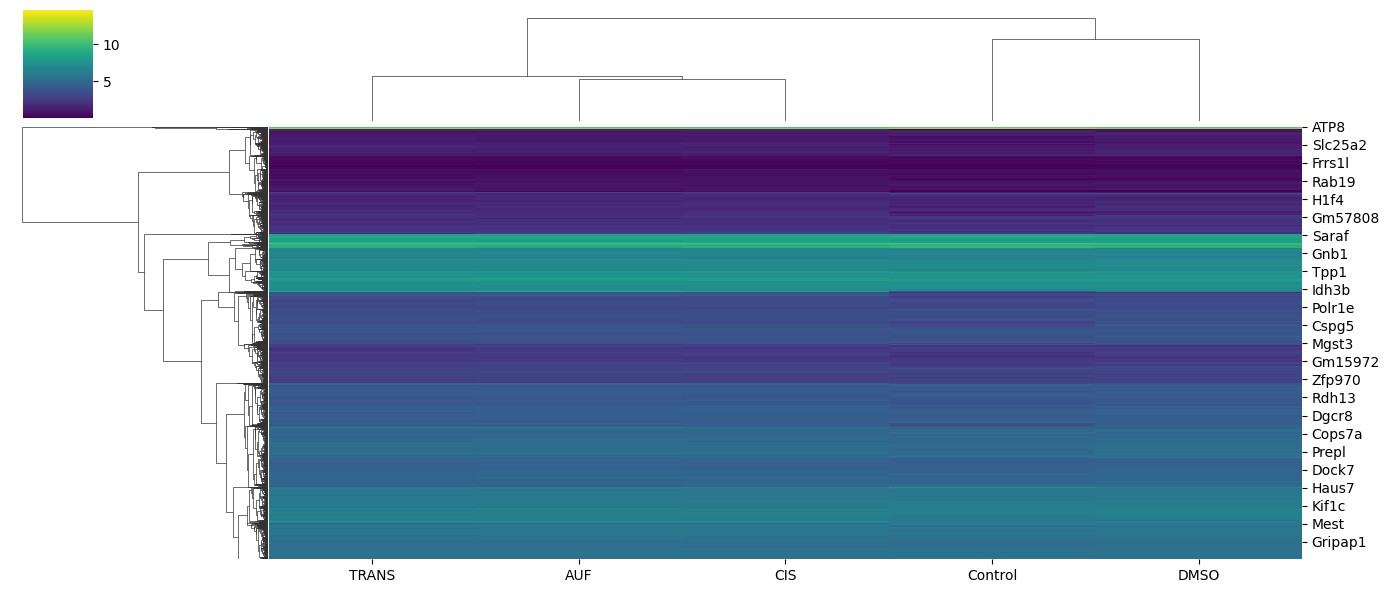

In [27]:
clustermap_summarized_median(final_tpm, meta, 'z-score')
clustermap_summarized_median(final_log, meta, None)
clustermap_summarized(final_tpm, meta, 'z-score')
clustermap_summarized(final_log, meta, None)